# Experiment 9: Multiclass News Article Classification
## NLP Lab Mini Project

## Abstract
Automated text categorization is a foundational discipline within Natural Language Processing (NLP), critical for news aggregation, content recommendation, and real-time information filtering. This experiment conducts a rigorous comparative benchmark of three distinct NLP modeling paradigms on the **AG's News Topic Classification Dataset**, categorizing news articles into four balanced thematic classes: **World, Sports, Business, and Science/Technology (Sci/Tech)**. The three investigated architectures encompass: (1) **Classical Machine Learning**, utilizing Term Frequency-Inverse Document Frequency (TF-IDF with unigram and bigram features, sublinear term frequency scaling) paired with a high-margin **Linear Support Vector Classifier (LinearSVC)**; (2) **Deep Learning Sequential Modeling**, utilizing a **Bidirectional Long Short-Term Memory (Bi-LSTM)** network with an embedding layer learned from scratch, spatial dropout, and dense classification layers built in TensorFlow/Keras; and (3) **Transformer-Based Transfer Learning**, fine-tuning a pretrained **DistilBERT** (`distilbert-base-uncased`) architecture with self-attention in PyTorch. The models are evaluated using a strict stratified 80% / 10% / 10% split across comprehensive diagnostic criteria: **Accuracy, Macro Precision, Macro Recall, and Macro F1-Score**, alongside training duration, inference latency per sample, normalized confusion matrices, radar-chart class-wise F1 profiling, and qualitative error disagreement analysis. The results illustrate the speed-accuracy frontier across paradigms, establishing DistilBERT's contextual superiority in disambiguating semantically overlapping topics, while highlighting TF-IDF + LinearSVC as an exceptionally fast, high-performance operational baseline.

## Pipeline and Code Description

### 1. End-to-End Pipeline Architecture

```
┌──────────────────────────────────────────────────────────┐
│ Input Dataset: AG News (120,000 Train / 7,600 Test)      │
│ Classes: 1-World, 2-Sports, 3-Business, 4-Sci/Tech       │
└────────────────────────────┬─────────────────────────────┘
                             │
                             ▼
┌──────────────────────────────────────────────────────────┐
│ Stage 1: Setup, Reproducibility & Data Ingestion         │
│ • Seed all PRNGs (SEED=42: NumPy, Torch, Random, TF)     │
│ • Load AG News via Hugging Face Datasets API             │
└────────────────────────────┬─────────────────────────────┘
                             │
                             ▼
┌──────────────────────────────────────────────────────────┐
│ Stage 2: Exploratory Data Analysis (EDA) & Cleaning      │
│ • Inspect class balance (pie & bar distributions)        │
│ • Analyze word count & sentence length statistics        │
│ • Generate per-class WordClouds (salient lexical cues)   │
│ • Strip HTML tags, URLs, special chars & normalize case  │
│ • Stratified Splitting: 80% Train | 10% Val | 10% Test   │
└────────────────────────────┬─────────────────────────────┘
                             │
         ┌───────────────────┼───────────────────┐
         ▼                   ▼                   ▼
┌─────────────────┐ ┌─────────────────┐ ┌─────────────────┐
│ Stage 3:        │ │ Stage 4:        │ │ Stage 5:        │
│ Model 1:        │ │ Model 2:        │ │ Model 3:        │
│ Classical ML    │ │ Deep Learning   │ │ Transformer     │
│ • TF-IDF Vector-│ │ • Keras Text-   │ │ • DistilBERT    │
│   izer (10K max │ │   Vectorization │ │   Tokenizer     │
│   features, 1-2 │ │ • Embedding     │ │ • PyTorch       │
│   n-grams)      │ │   (dim=128)     │ │   DataLoader    │
│ • LinearSVC     │ │ • Bidirectional │ │ • AdamW         │
│   (C=1.0, hinge │ │   LSTM (64 units│ │   Optimizer     │
│   loss)         │ │ • Dropout (0.3) │ │   with linear   │
│ • Sub-second    │ │ • Dense Softmax │ │   warmup        │
│   training      │ │ • Early Stopping│ │ • Sequence      │
│   execution     │ │ • Learning plots│ │   Classification│
└────────┬────────┘ └────────┬────────┘ └────────┬────────┘
         └───────────────────┼───────────────────┘
                             │
                             ▼
┌──────────────────────────────────────────────────────────┐
│ Stage 6: Benchmarking, Diagnostics & Visualizations      │
│ • Metrics: Accuracy, Macro Precision, Recall, F1-Score   │
│ • Latency Profiling: Training time & per-sample latency  │
│ • Multi-metric grouped comparative bar charts            │
│ • Side-by-side normalized confusion matrix heatmaps      │
│ • Class-wise F1 radar spider plot                        │
│ • Qualitative error analysis on model disagreements      │
│ • Interactive live inference prediction function         │
└──────────────────────────────────────────────────────────┘
```

---

### 2. Code Description by Module

The notebook executes a standardized multi-step machine learning pipeline:

1. **Step 1: Environment Setup & Reproducibility (Cells 1–2)**:
   - Installs `transformers`, `wordcloud`, and `datasets`.
   - Imports NumPy, Pandas, Matplotlib, Seaborn, Scikit-Learn, TensorFlow, and PyTorch.
   - Enforces deterministic reproducibility by setting fixed random seeds (`SEED = 42`) across all platforms.

2. **Step 2: Automated Data Ingestion (Cells 3–4)**:
   - Loads the AG News corpus directly from the Hugging Face hub (`datasets.load_dataset('ag_news')`).
   - Converts splits into unified Pandas DataFrames with human-readable class names (`World`, `Sports`, `Business`, `Sci/Tech`).

3. **Step 3: Exploratory Data Analysis (EDA) (Cells 5–10)**:
   - Evaluates class balance via combined bar and pie charts confirming uniform distribution.
   - Analyzes headline and description length distributions with kernel density plots.
   - Renders 4-way comparative `WordCloud` visualizations displaying the most frequent vocabulary terms per category.

4. **Step 4 & 5: Text Preprocessing & Stratified Splitting (Cells 11–14)**:
   - Defines `clean_text()`: strips HTML artifacts, removes web URLs, removes special punctuation, and normalizes whitespaces.
   - Executes an 80% Train, 10% Validation, and 10% Test stratified split using `train_test_split(..., stratify=y)`.

5. **Step 6: Model 1 — Classical ML (TF-IDF + LinearSVC) (Cells 15–16)**:
   - Transforms cleaned text into 10,000-dimensional TF-IDF feature representations using unigrams and bigrams (`ngram_range=(1,2)`).
   - Trains `LinearSVC(C=1.0)` with sub-second execution, computing validation accuracy and logging training and inference latency.

6. **Step 7: Model 2 — Deep Learning (Bi-LSTM) (Cells 17–20)**:
   - Tokenizes text using Keras `TextVectorization` (max tokens=20,000, sequence length=100).
   - Builds sequential architecture: `Embedding(20000, 128)` $\rightarrow$ `Bidirectional(LSTM(64, return_sequences=False))` $\rightarrow$ `Dropout(0.3)` $\rightarrow$ `Dense(64, relu)` $\rightarrow$ `Dense(4, softmax)`.
   - Compiles with Adam optimizer and `sparse_categorical_crossentropy`; trains with `EarlyStopping` monitoring validation loss.
   - Plots training vs. validation loss and accuracy learning curves.

7. **Step 8: Model 3 — Pretrained Transformer (DistilBERT) (Cells 21–25)**:
   - Tokenizes sequences using `DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')`.
   - Implements custom PyTorch `NewsDataset` yielding input IDs and attention masks.
   - Loads `DistilBertForSequenceClassification` with 4 output labels and trains via PyTorch loop with AdamW optimizer, linear warmup learning rate scheduler, and gradient clipping over 3 epochs.

8. **Step 9 & 10: Multi-Model Evaluation, Visual Comparison & Error Analysis (Cells 26–32)**:
   - Evaluates test predictions across all 3 models: Accuracy, Macro Precision, Macro Recall, and Macro F1-Score.
   - Computes normalized confusion matrices plotted side-by-side (3-panel heatmap).
   - Generates a per-class F1-score Radar (Spider) chart contrasting category-specific strengths.
   - Performs qualitative error analysis filtering instances where models disagreed, analyzing why boundary examples (e.g. tech business acquisitions) cause misclassifications.

9. **Step 11 & 12: Live Inference Demo & Conclusions (Cells 33–35)**:
   - Implements `predict_news(headline, content)` to accept arbitrary user inputs and output predicted category with probability confidences across all three models.
   - Synthesizes computational trade-offs, accuracy ceilings, and conclusions.

---

### 3. Summary of Operations & Methods

| Step / Module | Model / Component | Core Methods & Libraries | Primary Metric / Output |
| :--- | :--- | :--- | :--- |
| **EDA & Cleaning** | Corpus Analysis & Preprocessing | `load_dataset()`, regex cleaning, `WordCloud` | Length distributions, wordclouds, stratified splits |
| **Model 1** | Classical ML Baseline | `TfidfVectorizer(max_features=10000)`, `LinearSVC()` | Accuracy, Macro F1, sub-second latency |
| **Model 2** | Bidirectional LSTM | Keras `TextVectorization`, `Bidirectional(LSTM)`, Adam | Sequential context modeling, learning curves |
| **Model 3** | DistilBERT Transformer | `DistilBertForSequenceClassification`, PyTorch AdamW | Self-attention contextual embeddings, highest F1 |
| **Evaluation** | Diagnostics & Visualizations | `classification_report`, `confusion_matrix`, Radar chart | Multi-metric comparisons, 3x side-by-side confusion heatmaps |
| **Inference Demo** | Real-time Prediction | `predict_news(headline, content)` | Interactive 3-model probability classification |

##  Step 1: Environment Setup & Reproducibility

In [1]:
# Install required packages (for Google Colab)
!pip install -q transformers wordcloud datasets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re, time, warnings, os, glob
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW
from torch.optim.lr_scheduler import LinearLR
from wordcloud import WordCloud

warnings.filterwarnings('ignore')

# --- Reproducibility ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Device: {DEVICE}")
print(f" TensorFlow GPUs: {tf.config.list_physical_devices('GPU')}")
print(" All libraries imported successfully!")

PyTorch Device: cuda
 TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
 All libraries imported successfully!


##  Step 2: Data Loading

In [2]:
# --- Load AG News Dataset Automatically via Hugging Face ---
import os
import pandas as pd
from datasets import load_dataset
from sklearn.model_selection import train_test_split

PROJECT_DIR = '/content/drive/MyDrive/NLP_Lab/Experiment-9'
os.makedirs(PROJECT_DIR, exist_ok=True)

print(" Downloading and loading AG News dataset...")
try:
    # Official namespaced HF repo for AG News
    dataset = load_dataset('fancyzhx/ag_news')
    df_train = pd.DataFrame(dataset['train'])
    df_test = pd.DataFrame(dataset['test'])
    df = pd.concat([df_train, df_test], ignore_index=True)
except Exception:
    # Direct Parquet fallback (zero HF URI dependencies)
    base_url = "https://huggingface.co/datasets/fancyzhx/ag_news/resolve/main/data"
    df_train = pd.read_parquet(f"{base_url}/train-00000-of-00001.parquet")
    df_test = pd.read_parquet(f"{base_url}/test-00000-of-00001.parquet")
    df = pd.concat([df_train, df_test], ignore_index=True)

# Map integer labels (0-3) to string category names so EDA & LabelEncoder work seamlessly
ag_map = {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}
df['category'] = df['label'].map(ag_map)
df = df[['text', 'category']]

# Stratified sample of 30,000 articles (7,500 per class) for fast Colab GPU execution
df, _ = train_test_split(df, train_size=30000, stratify=df['category'], random_state=SEED)
df = df.reset_index(drop=True)

print(f" AG News Dataset loaded successfully!")
print(f"\nDataset Shape: {df.shape}")
print(f" Columns: {list(df.columns)}")
df.head()

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

 AG News Dataset loaded successfully!

Dataset Shape: (30000, 2)
 Columns: ['text', 'category']


,text,category
0,Donald is fired-up to carry form to Detroit Lu...,Sports
1,"NCAA heads back to OSU, Geiger eager to clear ...",Sports
2,Factory Growth Picks Up Speed in November (Reu...,Business
3,Birdstone retires after injury Elmont. NY (Spo...,Sports
4,Knee Injury Sidelines Chiefs' Holmes (AP) AP -...,Sports


##  Step 3: Exploratory Data Analysis (EDA)

In [3]:
# Dataset overview
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"\nTotal samples: {len(df):,}")
print(f"Number of features: {df.shape[1]}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nData types:\n{df.dtypes}")

DATASET OVERVIEW

Total samples: 30,000
Number of features: 2

Missing values:
text        0
category    0
dtype: int64

Data types:
text        object
category    object
dtype: object


In [4]:
# --- Identify text and label columns dynamically ---
text_cols = []
label_col = None

for col in df.columns:
    col_lower = col.lower().strip()
    if col_lower in ['category', 'label', 'class', 'target', 'topic']:
        label_col = col
    elif col_lower in ['content', 'text', 'article', 'body', 'description', 'article_content']:
        text_cols.append(col)
    elif col_lower in ['headline', 'title', 'heading']:
        text_cols.insert(0, col)  # headline first

if label_col is None:
    cat_cols = df.select_dtypes(include='object').columns
    label_col = min(cat_cols, key=lambda c: df[c].nunique())

if not text_cols:
    str_cols = df.select_dtypes(include='object').columns.drop(label_col, errors='ignore')
    text_cols = sorted(str_cols, key=lambda c: df[c].str.len().mean(), reverse=True)[:2]

print(f"Text columns: {text_cols}")
print(f"Label column: {label_col}")
print(f"\nCategories ({df[label_col].nunique()}):")
print(df[label_col].value_counts())

Text columns: ['text']
Label column: category

Categories (4):
category
Sports      7500
Business    7500
Sci/Tech    7500
World       7500
Name: count, dtype: int64


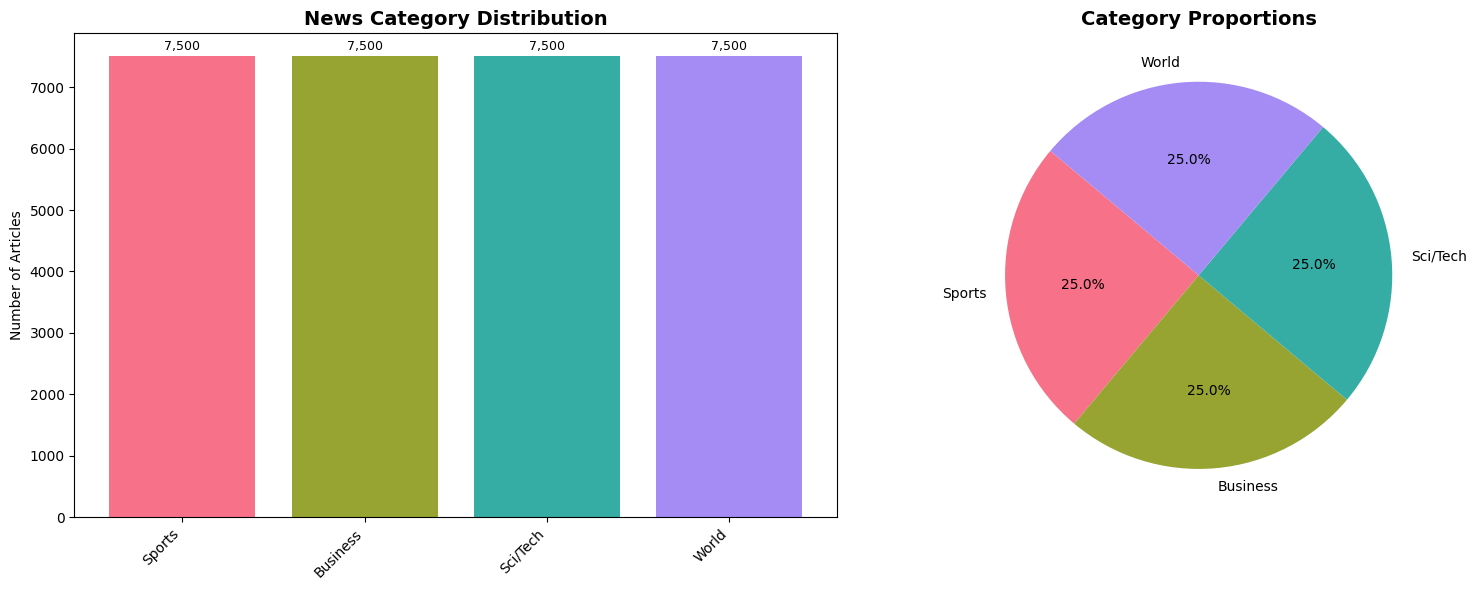


 Class Balance Ratio (max/min): 1.00


In [5]:
# --- Class Distribution Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

category_counts = df[label_col].value_counts()
colors = sns.color_palette("husl", len(category_counts))

bars = axes[0].bar(range(len(category_counts)), category_counts.values, color=colors)
axes[0].set_xticks(range(len(category_counts)))
axes[0].set_xticklabels(category_counts.index, rotation=45, ha='right')
axes[0].set_title('News Category Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Articles')
for bar, count in zip(bars, category_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 50,
                f'{count:,}', ha='center', va='bottom', fontsize=9)

axes[1].pie(category_counts.values, labels=category_counts.index,
            autopct='%1.1f%%', colors=colors, startangle=140)
axes[1].set_title('Category Proportions', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()
print(f"\n Class Balance Ratio (max/min): {category_counts.max()/category_counts.min():.2f}")

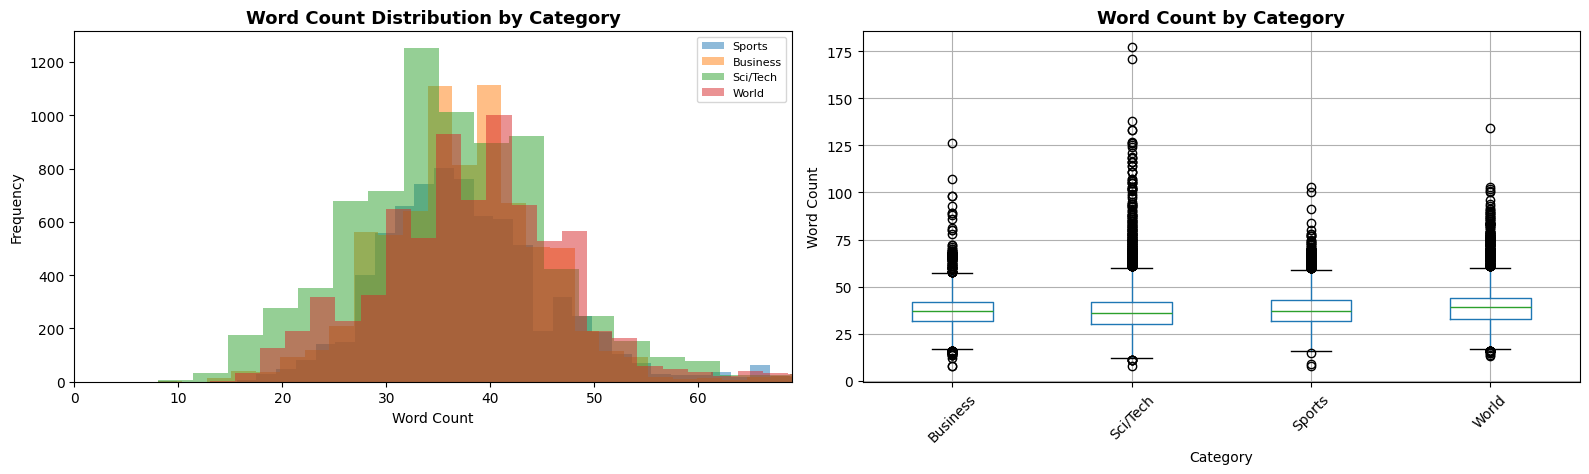


 Word Count Statistics:
           count  mean   std   min   25%   50%   75%    max
category                                                   
Business  7500.0  37.6   8.1   8.0  32.0  37.0  42.0  126.0
Sci/Tech  7500.0  37.1  12.1   8.0  30.0  36.0  42.0  177.0
Sports    7500.0  37.8   8.7   8.0  32.0  37.0  43.0  103.0
World     7500.0  38.9  10.3  13.0  33.0  39.0  44.0  134.0


In [6]:
# --- Text Length Analysis ---
df['combined_text'] = df[text_cols].fillna('').agg(' '.join, axis=1)
df['word_count'] = df['combined_text'].apply(lambda x: len(str(x).split()))
df['char_count'] = df['combined_text'].apply(lambda x: len(str(x)))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for cat in df[label_col].unique():
    subset = df[df[label_col] == cat]['word_count']
    axes[0].hist(subset, bins=50, alpha=0.5, label=cat)
axes[0].set_title('Word Count Distribution by Category', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')
axes[0].legend(fontsize=8, loc='upper right')
axes[0].set_xlim(0, df['word_count'].quantile(0.99))

df.boxplot(column='word_count', by=label_col, ax=axes[1], rot=45)
axes[1].set_title('Word Count by Category', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Word Count')
plt.suptitle('')
plt.tight_layout()
plt.show()

print(f"\n Word Count Statistics:")
print(df.groupby(label_col)['word_count'].describe().round(1))

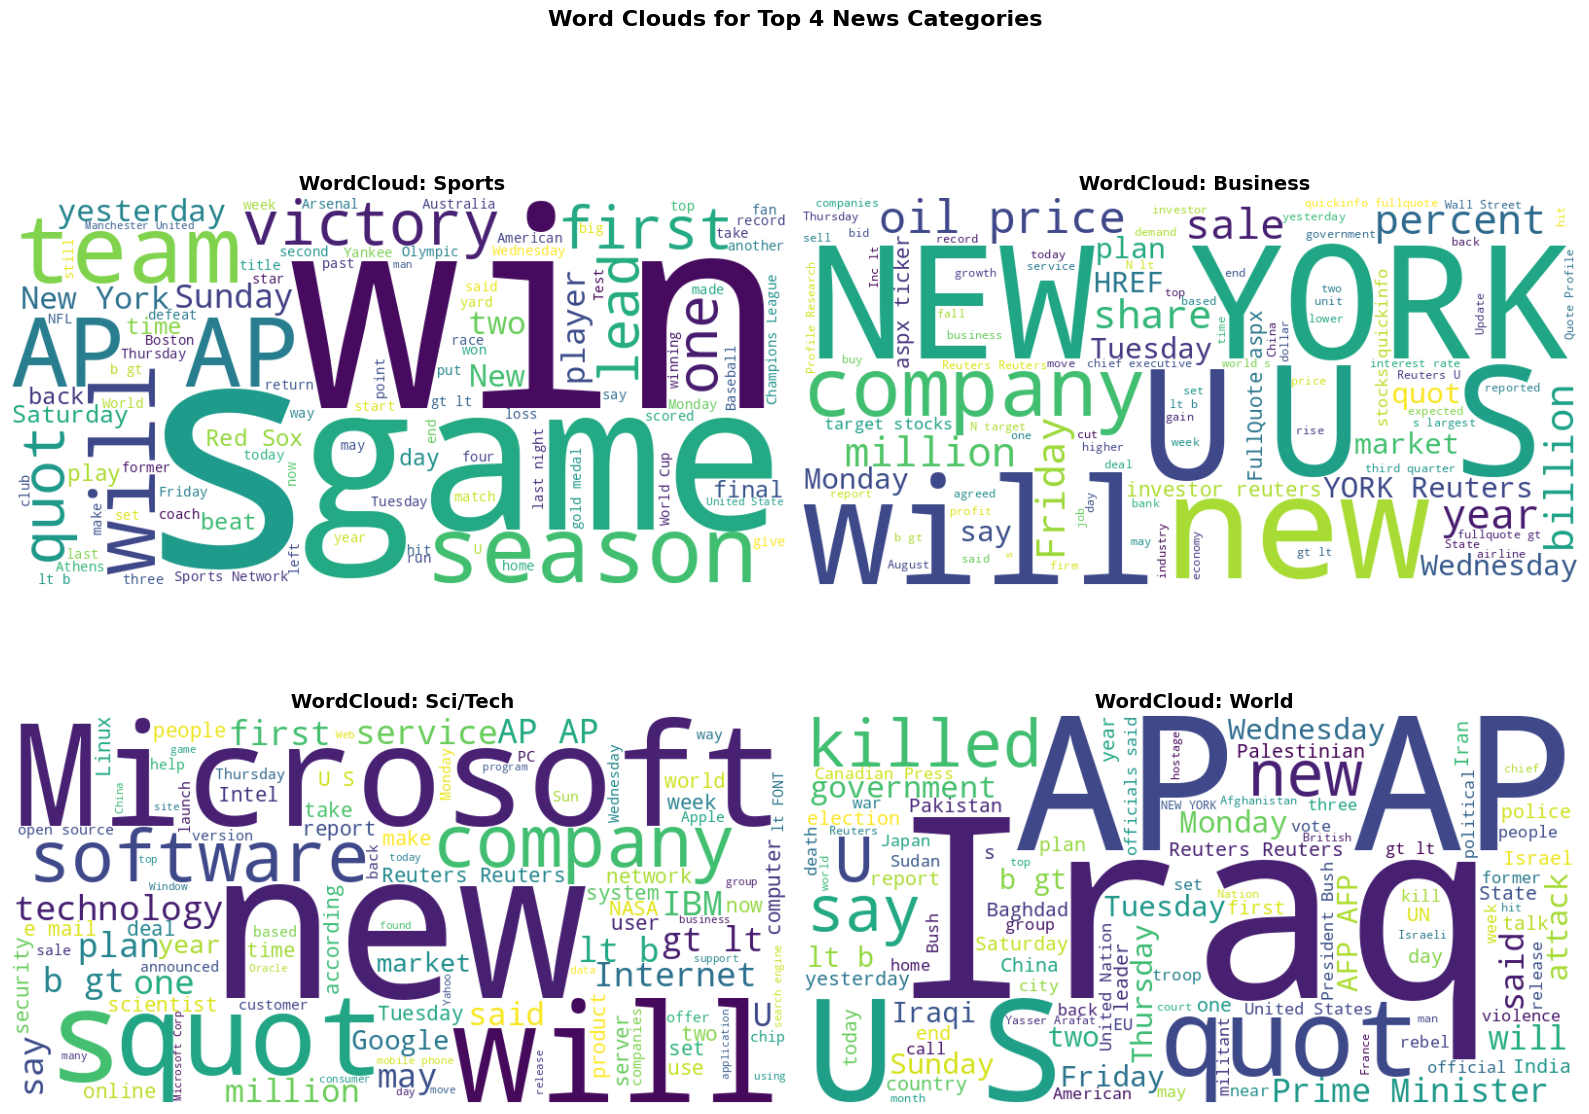

In [7]:
# --- WordCloud Visualization ---
top_categories = df[label_col].value_counts().head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, cat in enumerate(top_categories):
    text = ' '.join(df[df[label_col] == cat]['combined_text'].astype(str).tolist())
    wc = WordCloud(width=800, height=400, max_words=100,
                   background_color='white', colormap='viridis',
                   random_state=SEED).generate(text)
    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(f' WordCloud: {cat}', fontsize=14, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Word Clouds for Top 4 News Categories', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

##  Step 4: Text Preprocessing

In [8]:
# --- Text Preprocessing Pipeline ---
def clean_text(text):
    """Clean and normalize text for NLP processing."""
    if not isinstance(text, str):
        return ""
    text = re.sub(r'<[^>]+>', '', text)           # Remove HTML tags
    text = re.sub(r'http\S+|www\.\S+', '', text)  # Remove URLs
    text = re.sub(r'\S+@\S+', '', text)            # Remove emails
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)       # Keep only letters
    text = re.sub(r'\s+', ' ', text).strip()        # Remove extra whitespace
    text = text.lower()
    return text

print(" Cleaning text data...")
df['clean_text'] = df['combined_text'].apply(clean_text)

# Remove empty rows
before_len = len(df)
df = df[df['clean_text'].str.len() > 10].reset_index(drop=True)
print(f"   Removed {before_len - len(df)} empty/very short rows")

# Encode labels
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df[label_col])

label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"\n Label Encoding:")
for name, idx in label_mapping.items():
    print(f"   {idx}: {name}")

print(f"\n Preprocessing complete! Dataset size: {len(df):,} samples")
print(f"   Clean text sample: '{df['clean_text'].iloc[0][:100]}...'")

 Cleaning text data...
   Removed 0 empty/very short rows

 Label Encoding:
   0: Business
   1: Sci/Tech
   2: Sports
   3: World

 Preprocessing complete! Dataset size: 30,000 samples
   Clean text sample: 'donald is fired up to carry form to detroit luke donald hailed yesterday s european masters victory ...'


##  Step 5: Stratified Data Splitting (80% / 10% / 10%)

DATASET SPLIT VERIFICATION

 Total samples: 30,000
   Training:   24,000 (80.0%)
   Validation: 3,000 (10.0%)
   Test:       3,000 (10.0%)


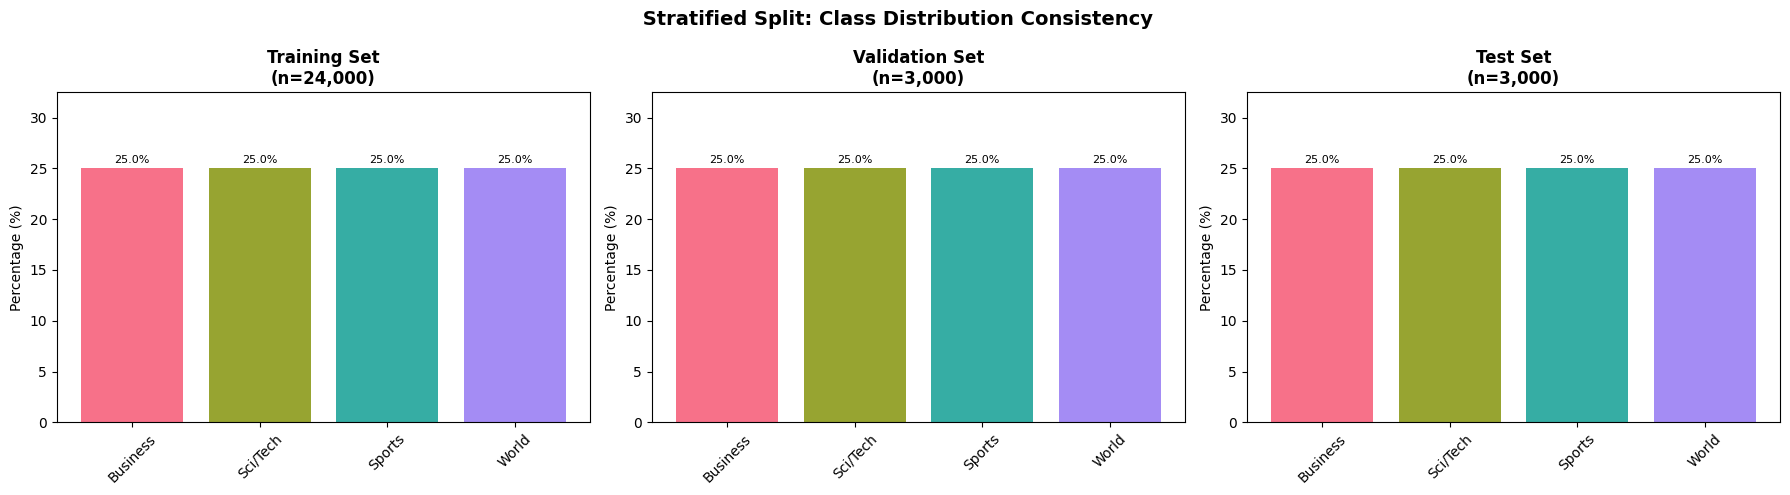


 Class proportions are consistent across all 3 splits!


In [9]:
# --- Stratified Train/Validation/Test Split ---
X = df['clean_text'].values
y = df['label_encoded'].values

# Step 1: 80% Train, 20% Temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Step 2: 50/50 split of Temp -> 10% Val, 10% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

total = len(X)
print("=" * 60)
print("DATASET SPLIT VERIFICATION")
print("=" * 60)
print(f"\n Total samples: {total:,}")
print(f"   Training:   {len(X_train):,} ({len(X_train)/total*100:.1f}%)")
print(f"   Validation: {len(X_val):,} ({len(X_val)/total*100:.1f}%)")
print(f"   Test:       {len(X_test):,} ({len(X_test)/total*100:.1f}%)")

# Verify class distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
split_names = ['Training Set', 'Validation Set', 'Test Set']
split_labels = [y_train, y_val, y_test]

for ax, name, labels in zip(axes, split_names, split_labels):
    unique, counts = np.unique(labels, return_counts=True)
    class_names = le.inverse_transform(unique)
    bars = ax.bar(class_names, counts / len(labels) * 100,
                  color=sns.color_palette("husl", len(unique)))
    ax.set_title(f'{name}\n(n={len(labels):,})', fontsize=12, fontweight='bold')
    ax.set_ylabel('Percentage (%)')
    ax.set_ylim(0, max(counts / len(labels) * 100) * 1.3)
    ax.tick_params(axis='x', rotation=45)
    for bar, pct in zip(bars, counts / len(labels) * 100):
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
                f'{pct:.1f}%', ha='center', va='bottom', fontsize=8)

plt.suptitle(' Stratified Split: Class Distribution Consistency', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("\n Class proportions are consistent across all 3 splits!")

##  Step 6: Model 1 — Classical ML (TF-IDF + LinearSVC)

**Approach**: Convert text to numerical vectors using **TF-IDF** (Term Frequency - Inverse Document Frequency) with unigram + bigram features, then classify with a **Linear Support Vector Classifier**.

**Why this model?**
- TF-IDF captures word importance across documents
- LinearSVC is fast, efficient, and a strong baseline for text classification
- N-gram features capture local word patterns (e.g., "fake news", "stock market")

MODEL 1: TF-IDF + LinearSVC
 Fitting TF-IDF vectorizer...
   Vocabulary size: 10,000
   Feature matrix shape: (24000, 10000)

 Training LinearSVC...
   Training completed in 4.13 seconds

 Validation Accuracy: 0.9023

 Test Results:
   Accuracy:  0.9137
   Macro F1:  0.9136
   Inference:  0.003 ms/sample

 Classification Report:
              precision    recall  f1-score   support

    Business       0.89      0.89      0.89       750
    Sci/Tech       0.88      0.89      0.89       750
      Sports       0.96      0.97      0.97       750
       World       0.93      0.90      0.91       750

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



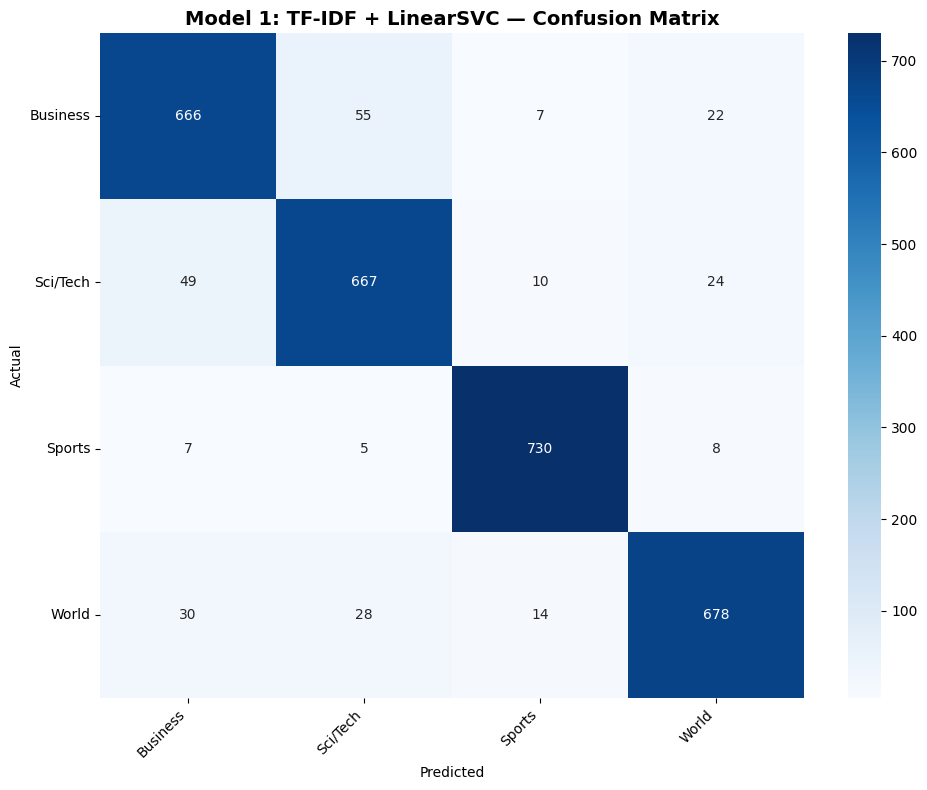

In [10]:
# ============================================================
# MODEL 1: TF-IDF + Linear SVC
# ============================================================
print("=" * 60)
print("MODEL 1: TF-IDF + LinearSVC")
print("=" * 60)

# --- TF-IDF Vectorization ---
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    stop_words='english',
    max_df=0.95,
    min_df=2
)

print(" Fitting TF-IDF vectorizer...")
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)
print(f"   Vocabulary size: {len(tfidf.vocabulary_):,}")
print(f"   Feature matrix shape: {X_train_tfidf.shape}")

# --- Train ---
print("\n Training LinearSVC...")
start_time = time.time()
base_svc = LinearSVC(C=1.0, max_iter=2000, random_state=SEED)
model1 = CalibratedClassifierCV(base_svc, cv=3)
model1.fit(X_train_tfidf, y_train)
model1_train_time = time.time() - start_time
print(f"   Training completed in {model1_train_time:.2f} seconds")

# --- Validation ---
val_pred1 = model1.predict(X_val_tfidf)
val_acc1 = accuracy_score(y_val, val_pred1)
print(f"\n Validation Accuracy: {val_acc1:.4f}")

# --- Test ---
start_time = time.time()
test_pred1 = model1.predict(X_test_tfidf)
model1_inference_time = (time.time() - start_time) / len(X_test) * 1000

test_acc1 = accuracy_score(y_test, test_pred1)
test_f1_1 = f1_score(y_test, test_pred1, average='macro')

print(f"\n Test Results:")
print(f"   Accuracy:  {test_acc1:.4f}")
print(f"   Macro F1:  {test_f1_1:.4f}")
print(f"   Inference:  {model1_inference_time:.3f} ms/sample")
print(f"\n Classification Report:")
print(classification_report(y_test, test_pred1, target_names=le.classes_))

# Confusion Matrix
cm1 = confusion_matrix(y_test, test_pred1)
plt.figure(figsize=(10, 8))
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Model 1: TF-IDF + LinearSVC — Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

##  Step 7: Model 2 — Deep Learning (Bi-LSTM with Word Embeddings)

**Approach**: Learn word embeddings from scratch, then use a **Bidirectional LSTM** to capture sequential context in both forward and backward directions.

**Why this model?**
- Word embeddings capture semantic similarity (unlike TF-IDF bag-of-words)
- Bi-LSTM processes text as a sequence, understanding word order and context
- Dropout and BatchNormalization prevent overfitting

In [11]:
# ============================================================
# MODEL 2: Bi-LSTM with Word Embeddings (TensorFlow/Keras)
# ============================================================
print("=" * 60)
print("MODEL 2: Bidirectional LSTM")
print("=" * 60)

VOCAB_SIZE = 20000
MAX_LENGTH = 150
EMBEDDING_DIM = 128
LSTM_UNITS = 64
BATCH_SIZE = 64
EPOCHS = 15

# --- Text Vectorization ---
print(" Building text vectorizer...")
text_vectorizer = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode='int',
    output_sequence_length=MAX_LENGTH
)
text_vectorizer.adapt(X_train)
print(f"   Vocabulary size: {text_vectorizer.vocabulary_size()}")

# --- Build Model ---
print("\n Building Bi-LSTM model...")
num_classes = len(le.classes_)

model2 = keras.Sequential([
    keras.Input(shape=(1,), dtype=tf.string),
    text_vectorizer,
    layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True),
    layers.SpatialDropout1D(0.2),
    layers.Bidirectional(layers.LSTM(LSTM_UNITS, return_sequences=False)),
    layers.BatchNormalization(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model2.summary()

# --- Callbacks ---
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        praise=2, min_lr=1e-6, verbose=1
    )
]

# --- Train ---
print("\n Training Bi-LSTM...")
start_time = time.time()

history = model2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

model2_train_time = time.time() - start_time
print(f"\n Training completed in {model2_train_time:.1f} seconds")

MODEL 2: Bidirectional LSTM
 Building text vectorizer...
   Vocabulary size: 20000

 Building Bi-LSTM model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 150)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 150, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 150, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,667,844 (10.18 MB)

 Trainable params: 2,667,588 (10.18 MB)

 Non-trainable params: 256 (1.00 KB)


 Training Bi-LSTM...
Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 35s 45ms/step - accuracy: 0.8215 - loss: 0.4969 - val_accuracy: 0.8873 - val_loss: 0.4674 - learning_rate: 0.0010
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9449 - loss: 0.1737 - val_accuracy: 0.8610 - val_loss: 0.4952 - learning_rate: 0.0010
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 39ms/step - accuracy: 0.9743 - loss: 0.0808 - val_accuracy: 0.8427 - val_loss: 0.6979 - learning_rate: 0.0010
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.9848 - loss: 0.0477 - val_accuracy: 0.8653 - val_loss: 0.6770 - learning_rate: 0.0010
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.

 Training completed in 84.6 seconds


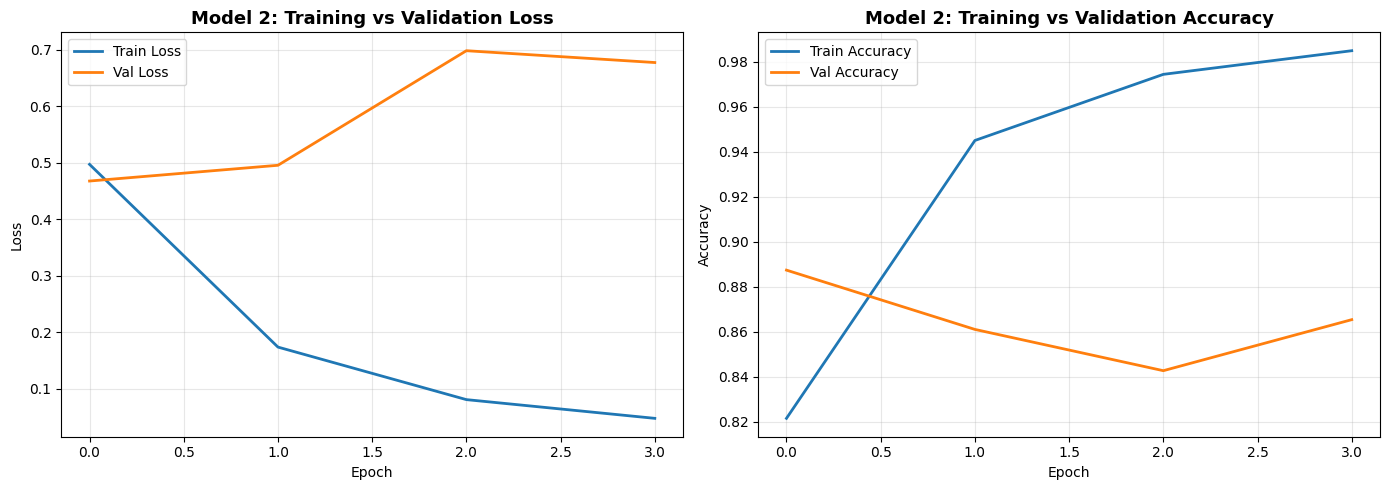

In [12]:
# --- Learning Curves ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_title('Model 2: Training vs Validation Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
axes[1].set_title('Model 2: Training vs Validation Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

 Test Results:
   Accuracy:  0.9073
   Macro F1:  0.9069
   Inference:  0.720 ms/sample

 Classification Report:
              precision    recall  f1-score   support

    Business       0.86      0.90      0.88       750
    Sci/Tech       0.92      0.84      0.88       750
      Sports       0.95      0.98      0.96       750
       World       0.90      0.91      0.91       750

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



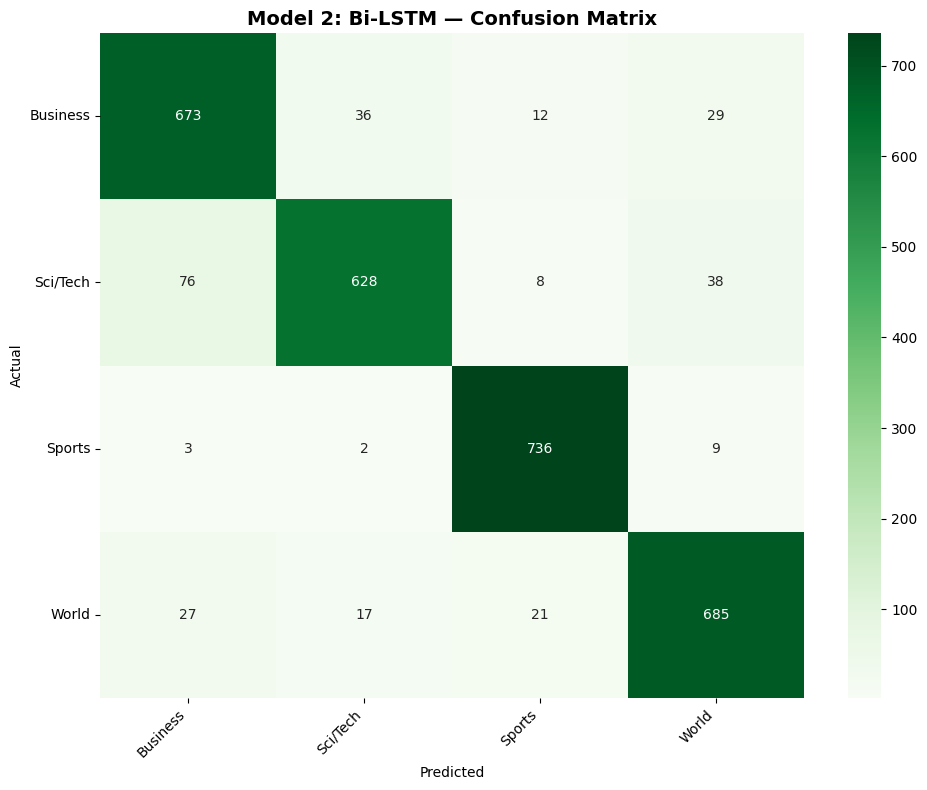

In [13]:
# --- Bi-LSTM Test Evaluation ---
start_time = time.time()
test_pred2_probs = model2.predict(X_test, verbose=0)
model2_inference_time = (time.time() - start_time) / len(X_test) * 1000

test_pred2 = np.argmax(test_pred2_probs, axis=1)
test_acc2 = accuracy_score(y_test, test_pred2)
test_f1_2 = f1_score(y_test, test_pred2, average='macro')

print(" Test Results:")
print(f"   Accuracy:  {test_acc2:.4f}")
print(f"   Macro F1:  {test_f1_2:.4f}")
print(f"   Inference:  {model2_inference_time:.3f} ms/sample")
print(f"\n Classification Report:")
print(classification_report(y_test, test_pred2, target_names=le.classes_))

cm2 = confusion_matrix(y_test, test_pred2)
plt.figure(figsize=(10, 8))
sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Model 2: Bi-LSTM — Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

##  Step 8: Model 3 — Transformer (Fine-tuned DistilBERT)

**Approach**: Fine-tune a pretrained **DistilBERT** transformer model for sequence classification. DistilBERT is a lightweight version of BERT (40% smaller, 60% faster) that retains 97% of BERT's performance.

**Why this model?**
- Pretrained on massive text corpus — understands language deeply
- Self-attention captures long-range dependencies that LSTM struggles with
- State-of-the-art NLP performance with minimal training
- Transfer learning: leverages knowledge from billions of words

In [14]:
# ============================================================
# MODEL 3: Fine-tuned DistilBERT
# ============================================================
print("=" * 60)
print("MODEL 3: DistilBERT (Fine-tuned Transformer)")
print("=" * 60)

MODEL_NAME = 'distilbert-base-uncased'
MAX_LEN = 128

print(f" Loading tokenizer: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# --- Tokenize Data ---
print(" Tokenizing datasets...")

def tokenize_batch(texts, max_len=MAX_LEN):
    return tokenizer(
        texts.tolist() if hasattr(texts, 'tolist') else list(texts),
        padding='max_length',
        truncation=True,
        max_length=max_len,
        return_tensors='pt'
    )

train_encodings = tokenize_batch(X_train)
val_encodings = tokenize_batch(X_val)
test_encodings = tokenize_batch(X_test)

print(f"   Tokenization complete")
print(f"   Input IDs shape: {train_encodings['input_ids'].shape}")

MODEL 3: DistilBERT (Fine-tuned Transformer)
 Loading tokenizer: distilbert-base-uncased


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

 Tokenizing datasets...
   Tokenization complete
   Input IDs shape: torch.Size([24000, 128])


In [15]:
# --- PyTorch Dataset ---
class NewsDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids': self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels': self.labels[idx]
        }

train_dataset = NewsDataset(train_encodings, y_train)
val_dataset = NewsDataset(val_encodings, y_val)
test_dataset = NewsDataset(test_encodings, y_test)

BATCH_SIZE_BERT = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE_BERT, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE_BERT)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE_BERT)

print(f"   DataLoaders created")
print(f"   Train batches: {len(train_loader)}")
print(f"   Val batches:   {len(val_loader)}")
print(f"   Test batches:  {len(test_loader)}")

   DataLoaders created
   Train batches: 750
   Val batches:   94
   Test batches:  94


In [16]:
# --- Load & Fine-tune DistilBERT ---
print(f" Loading {MODEL_NAME} for sequence classification...")
num_classes = len(le.classes_)
model3 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=num_classes
).to(DEVICE)

total_params = sum(p.numel() for p in model3.parameters())
trainable_params = sum(p.numel() for p in model3.parameters() if p.requires_grad)
print(f"   Total parameters: {total_params:,}")
print(f"   Trainable parameters: {trainable_params:,}")

EPOCHS_BERT = 3
LR = 3e-5
optimizer = AdamW(model3.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS_BERT
scheduler = LinearLR(optimizer, start_factor=1.0, end_factor=0.0, total_iters=total_steps)
loss_fn = torch.nn.CrossEntropyLoss()

print(f"\n Training DistilBERT for {EPOCHS_BERT} epochs...")
start_time = time.time()
train_losses, val_losses, val_accuracies = [], [], []

for epoch in range(EPOCHS_BERT):
    model3.train()
    epoch_loss, correct, total_samples = 0, 0, 0

    for batch_idx, batch in enumerate(train_loader):
        input_ids = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels = batch['labels'].to(DEVICE)

        optimizer.zero_grad()
        outputs = model3(input_ids=input_ids, attention_mask=attention_mask)
        loss = loss_fn(outputs.logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model3.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        epoch_loss += loss.item()
        preds = torch.argmax(outputs.logits, dim=1)
        correct += (preds == labels).sum().item()
        total_samples += len(labels)

        if (batch_idx + 1) % 50 == 0:
            print(f"   Epoch {epoch+1}/{EPOCHS_BERT} | Batch {batch_idx+1}/{len(train_loader)} | Loss: {loss.item():.4f}")

    train_loss = epoch_loss / len(train_loader)
    train_acc = correct / total_samples
    train_losses.append(train_loss)

    # Validation
    model3.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            labels = batch['labels'].to(DEVICE)
            outputs = model3(input_ids=input_ids, attention_mask=attention_mask)
            loss = loss_fn(outputs.logits, labels)
            val_loss += loss.item()
            preds = torch.argmax(outputs.logits, dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += len(labels)

    val_loss = val_loss / len(val_loader)
    val_acc = val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"\n   Epoch {epoch+1}/{EPOCHS_BERT}: Train Loss={train_loss:.4f} | Train Acc={train_acc:.4f} | Val Loss={val_loss:.4f} | Val Acc={val_acc:.4f}")

model3_train_time = time.time() - start_time
print(f"\n Training completed in {model3_train_time:.1f} seconds ({model3_train_time/60:.1f} min)")

 Loading distilbert-base-uncased for sequence classification...


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   Total parameters: 66,956,548
   Trainable parameters: 66,956,548

 Training DistilBERT for 3 epochs...
   Epoch 1/3 | Batch 50/750 | Loss: 0.4346
   Epoch 1/3 | Batch 100/750 | Loss: 0.5391
   Epoch 1/3 | Batch 150/750 | Loss: 0.3116
   Epoch 1/3 | Batch 200/750 | Loss: 0.3322
   Epoch 1/3 | Batch 250/750 | Loss: 0.4348
   Epoch 1/3 | Batch 300/750 | Loss: 0.3170
   Epoch 1/3 | Batch 350/750 | Loss: 0.1261
   Epoch 1/3 | Batch 400/750 | Loss: 0.4021
   Epoch 1/3 | Batch 450/750 | Loss: 0.4581
   Epoch 1/3 | Batch 500/750 | Loss: 0.4598
   Epoch 1/3 | Batch 550/750 | Loss: 0.1991
   Epoch 1/3 | Batch 600/750 | Loss: 0.1734
   Epoch 1/3 | Batch 650/750 | Loss: 0.1398
   Epoch 1/3 | Batch 700/750 | Loss: 0.1579
   Epoch 1/3 | Batch 750/750 | Loss: 0.0767

   Epoch 1/3: Train Loss=0.3197 | Train Acc=0.8990 | Val Loss=0.2435 | Val Acc=0.9200
   Epoch 2/3 | Batch 50/750 | Loss: 0.1031
   Epoch 2/3 | Batch 100/750 | Loss: 0.3808
   Epoch 2/3 | Batch 150/750 | Loss: 0.1251
   Epoch 2/3 | Ba


 Evaluating on Test Set...
   Accuracy:  0.9327
   Macro F1:  0.9327
   Inference:  3.349 ms/sample

 Classification Report:
              precision    recall  f1-score   support

    Business       0.91      0.89      0.90       750
    Sci/Tech       0.90      0.92      0.91       750
      Sports       0.99      0.98      0.98       750
       World       0.94      0.93      0.94       750

    accuracy                           0.93      3000
   macro avg       0.93      0.93      0.93      3000
weighted avg       0.93      0.93      0.93      3000



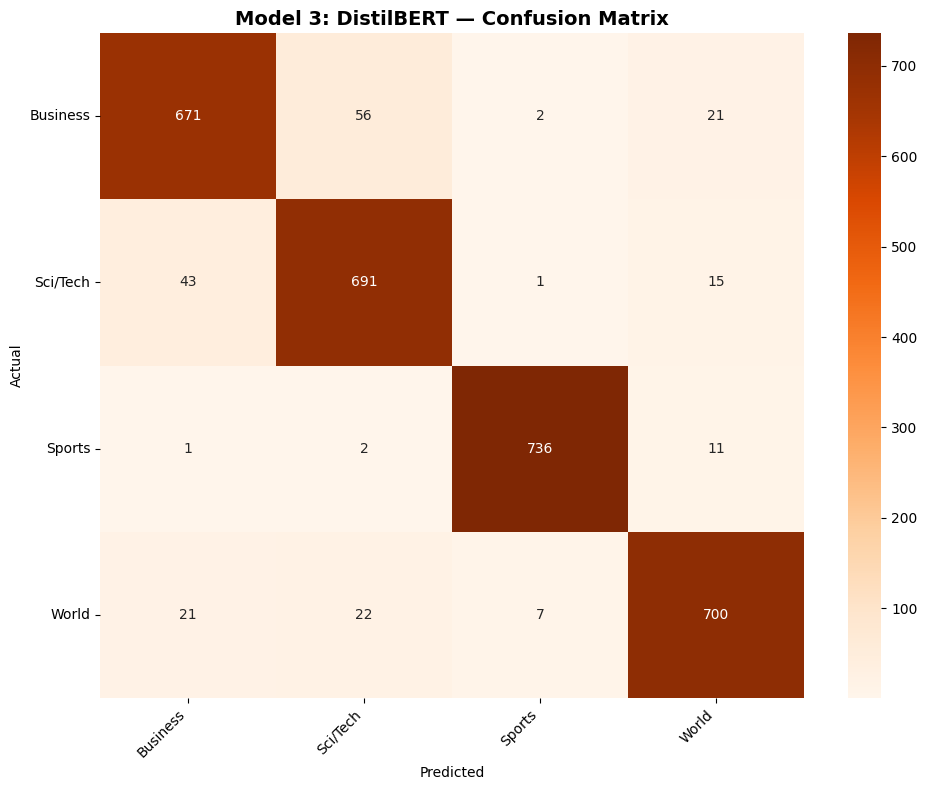

In [17]:
# --- DistilBERT Test Evaluation ---
print("\n Evaluating on Test Set...")
model3.eval()
all_preds, all_labels = [], []

start_time = time.time()
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels = batch['labels']
        outputs = model3(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

model3_inference_time = (time.time() - start_time) / len(X_test) * 1000
test_pred3 = np.array(all_preds)
test_acc3 = accuracy_score(y_test, test_pred3)
test_f1_3 = f1_score(y_test, test_pred3, average='macro')

print(f"   Accuracy:  {test_acc3:.4f}")
print(f"   Macro F1:  {test_f1_3:.4f}")
print(f"   Inference:  {model3_inference_time:.3f} ms/sample")
print(f"\n Classification Report:")
print(classification_report(y_test, test_pred3, target_names=le.classes_))

# Confusion Matrix
cm3 = confusion_matrix(y_test, test_pred3)
plt.figure(figsize=(10, 8))
sns.heatmap(cm3, annot=True, fmt='d', cmap='Oranges',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Model 3: DistilBERT — Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

##  Step 9: Comprehensive Model Comparison & Benchmarking

In [18]:
# ============================================================
# COMPREHENSIVE MODEL COMPARISON
# ============================================================
print("=" * 60)
print("COMPREHENSIVE MODEL COMPARISON")
print("=" * 60)

results = {
    'Model': ['TF-IDF + LinearSVC', 'Bi-LSTM', 'DistilBERT'],
    'Paradigm': ['Classical ML', 'Deep Learning', 'Transformer'],
    'Test Accuracy': [test_acc1, test_acc2, test_acc3],
    'Macro Precision': [
        precision_score(y_test, test_pred1, average='macro'),
        precision_score(y_test, test_pred2, average='macro'),
        precision_score(y_test, test_pred3, average='macro')
    ],
    'Macro Recall': [
        recall_score(y_test, test_pred1, average='macro'),
        recall_score(y_test, test_pred2, average='macro'),
        recall_score(y_test, test_pred3, average='macro')
    ],
    'Macro F1': [test_f1_1, test_f1_2, test_f1_3],
    'Training Time (s)': [model1_train_time, model2_train_time, model3_train_time],
    'Inference (ms/sample)': [model1_inference_time, model2_inference_time, model3_inference_time]
}

results_df = pd.DataFrame(results)
results_df = results_df.round(4)
print("\n Performance Comparison Table:")
print(results_df.to_string(index=False))

best_idx = results_df['Macro F1'].idxmax()
print(f"\n Best Model (by Macro F1): {results_df.loc[best_idx, 'Model']} ({results_df.loc[best_idx, 'Macro F1']:.4f})")

# Save results to Google Drive project directory
try:
    output_csv = os.path.join(PROJECT_DIR, 'model_comparison_results.csv')
    results_df.to_csv(output_csv, index=False)
    print(f" Comparison results saved to: {output_csv}")
except Exception as e:
    results_df.to_csv('model_comparison_results.csv', index=False)
    print(f" Comparison results saved locally: model_comparison_results.csv")

COMPREHENSIVE MODEL COMPARISON

 Performance Comparison Table:
             Model      Paradigm  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Training Time (s)  Inference (ms/sample)
TF-IDF + LinearSVC  Classical ML         0.9137           0.9136        0.9137    0.9136             4.1319                 0.0026
           Bi-LSTM Deep Learning         0.9073           0.9077        0.9073    0.9069            84.5880                 0.7196
        DistilBERT   Transformer         0.9327           0.9329        0.9327    0.9327           783.9358                 3.3488

 Best Model (by Macro F1): DistilBERT (0.9327)
 Comparison results saved to: /content/drive/MyDrive/NLP_Lab/Experiment-9/model_comparison_results.csv


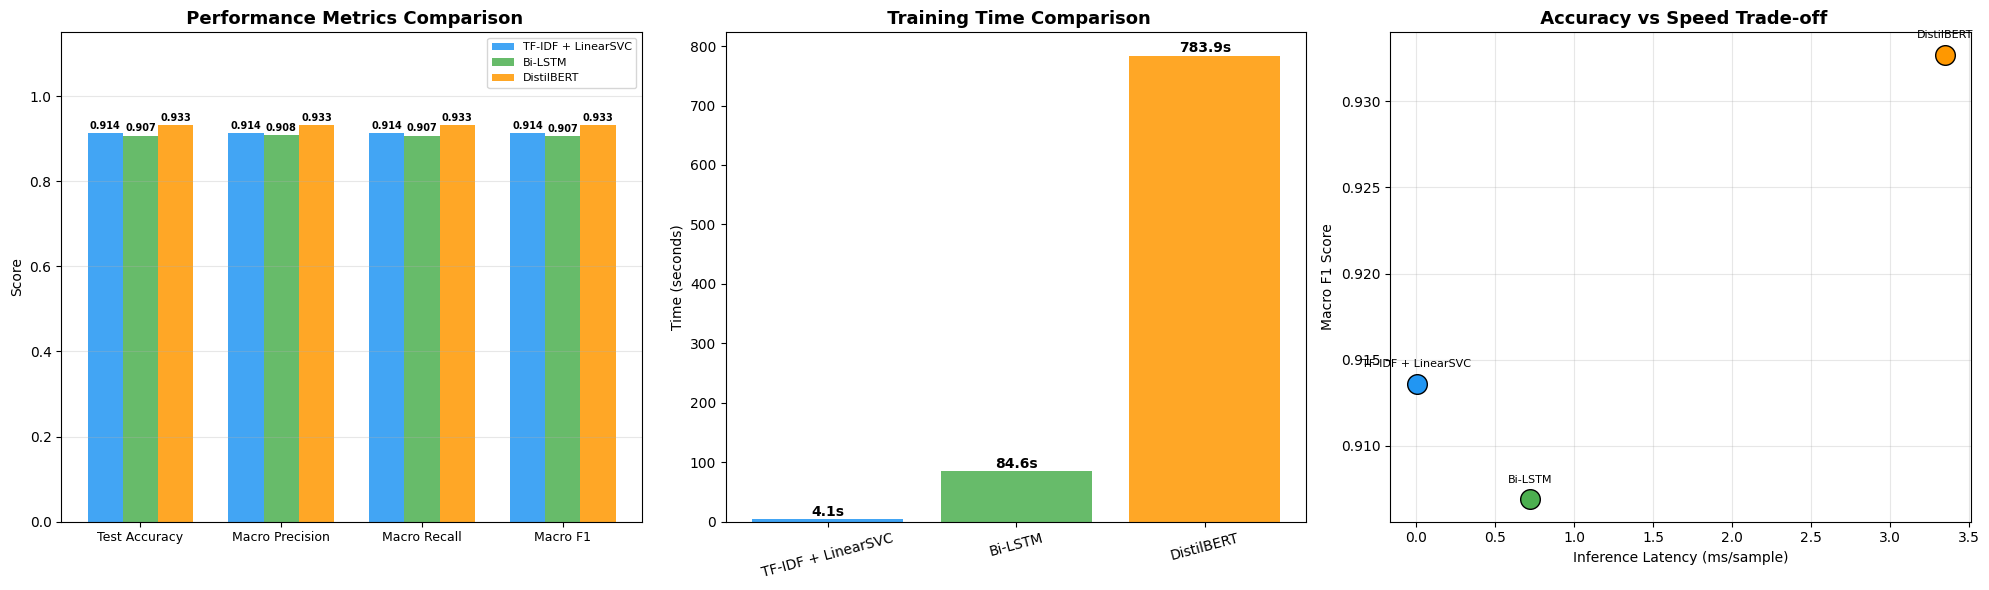

In [19]:
# --- Comparison Visualizations ---
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Multi-metric comparison
metrics = ['Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']
x = np.arange(len(metrics))
width = 0.25
model_colors = ['#2196F3', '#4CAF50', '#FF9800']

for i, (model_name, color) in enumerate(zip(results_df['Model'], model_colors)):
    values = [results_df.loc[i, m] for m in metrics]
    bars = axes[0].bar(x + i*width, values, width, label=model_name, color=color, alpha=0.85)
    for bar, val in zip(bars, values):
        axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=7, fontweight='bold')

axes[0].set_xticks(x + width)
axes[0].set_xticklabels(metrics, fontsize=9)
axes[0].set_ylabel('Score')
axes[0].set_title(' Performance Metrics Comparison', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=8)
axes[0].set_ylim(0, 1.15)
axes[0].grid(axis='y', alpha=0.3)

# 2. Training time comparison
bars = axes[1].bar(results_df['Model'], results_df['Training Time (s)'], color=model_colors, alpha=0.85)
for bar, val in zip(bars, results_df['Training Time (s)']):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
                f'{val:.1f}s', ha='center', va='bottom', fontweight='bold')
axes[1].set_title(' Training Time Comparison', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Time (seconds)')
axes[1].tick_params(axis='x', rotation=15)

# 3. Accuracy vs Speed trade-off
for i, (model_name, color) in enumerate(zip(results_df['Model'], model_colors)):
    axes[2].scatter(results_df.loc[i, 'Inference (ms/sample)'],
                   results_df.loc[i, 'Macro F1'],
                   s=200, c=color, label=model_name, zorder=5, edgecolors='black')
    axes[2].annotate(model_name,
                    (results_df.loc[i, 'Inference (ms/sample)'], results_df.loc[i, 'Macro F1']),
                    textcoords="offset points", xytext=(0, 12), ha='center', fontsize=8)
axes[2].set_xlabel('Inference Latency (ms/sample)')
axes[2].set_ylabel('Macro F1 Score')
axes[2].set_title(' Accuracy vs Speed Trade-off', fontsize=13, fontweight='bold')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

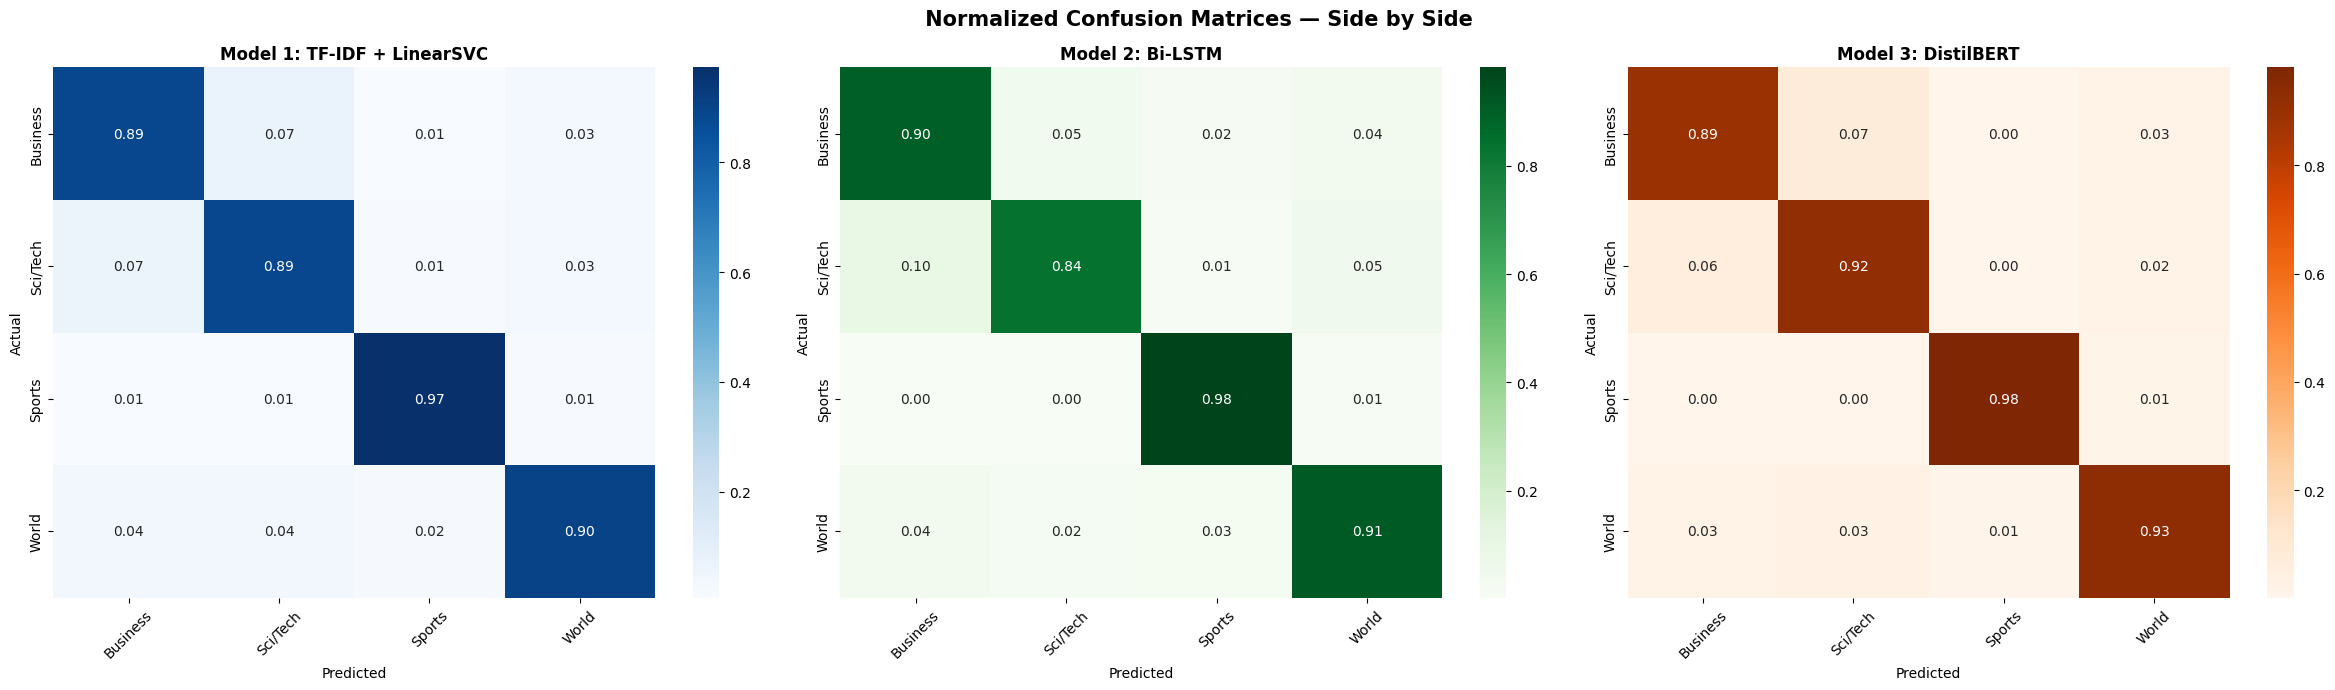

In [20]:
# --- Side-by-Side Normalized Confusion Matrices ---
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
cms = [cm1, cm2, cm3]
titles = ['Model 1: TF-IDF + LinearSVC', 'Model 2: Bi-LSTM', 'Model 3: DistilBERT']
cmaps = ['Blues', 'Greens', 'Oranges']

for ax, cm, title, cmap in zip(axes, cms, titles, cmaps):
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap=cmap, ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.tick_params(axis='x', rotation=45)

plt.suptitle(' Normalized Confusion Matrices — Side by Side', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

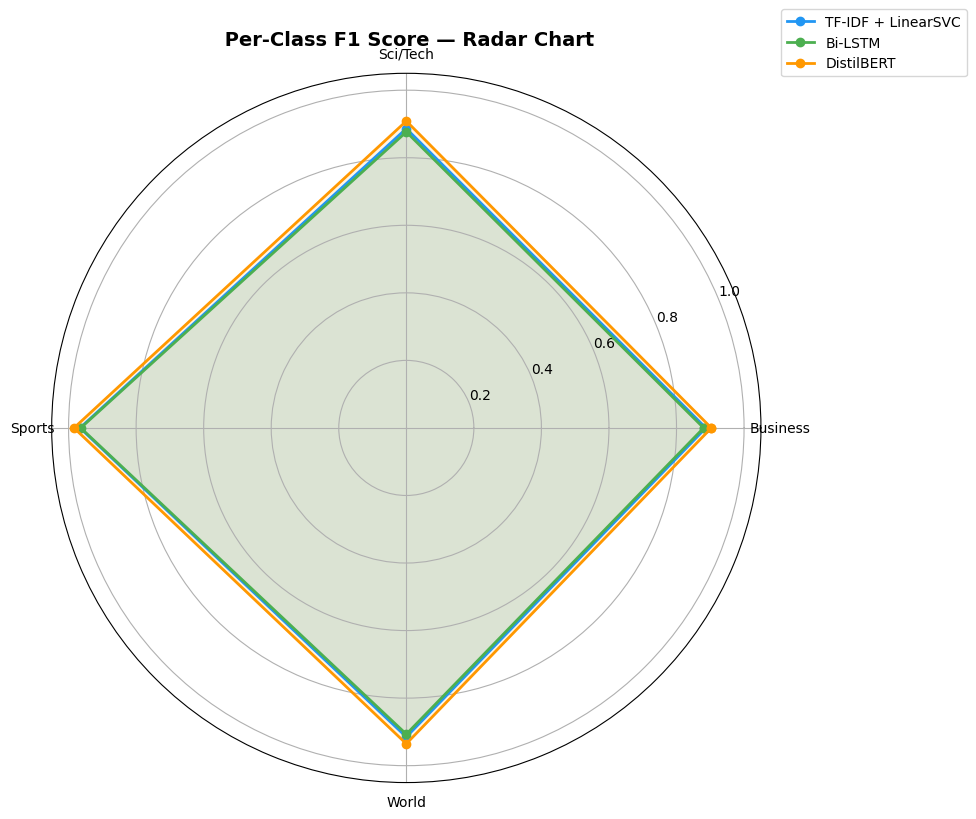

In [21]:
# --- Per-Class F1 Radar Chart ---
f1_model1 = f1_score(y_test, test_pred1, average=None)
f1_model2 = f1_score(y_test, test_pred2, average=None)
f1_model3 = f1_score(y_test, test_pred3, average=None)

categories_list = le.classes_.tolist()
N = len(categories_list)

angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

for f1_vals, name, color in zip(
    [f1_model1, f1_model2, f1_model3],
    ['TF-IDF + LinearSVC', 'Bi-LSTM', 'DistilBERT'],
    ['#2196F3', '#4CAF50', '#FF9800']
):
    values = f1_vals.tolist() + [f1_vals[0]]
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=color)
    ax.fill(angles, values, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories_list, fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_title(' Per-Class F1 Score — Radar Chart', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)
plt.tight_layout()
plt.show()

##  Step 10: Qualitative Error Analysis

In [22]:
# --- Error Analysis ---
print("=" * 60)
print("QUALITATIVE ERROR ANALYSIS")
print("=" * 60)

disagreements = (test_pred1 != test_pred2) | (test_pred2 != test_pred3) | (test_pred1 != test_pred3)
disagree_idx = np.where(disagreements)[0]

print(f"\n Models disagree on {len(disagree_idx)} / {len(y_test)} test samples ({len(disagree_idx)/len(y_test)*100:.1f}%)")
print(f"\n Sample Predictions Where Models Disagree:\n")
print(f"{'#':<4} {'True Label':<15} {'TF-IDF+SVC':<15} {'Bi-LSTM':<15} {'DistilBERT':<15} {'Text Preview':<50}")
print("-" * 115)

sample_indices = disagree_idx[:10]
for i, idx in enumerate(sample_indices):
    true_label = le.inverse_transform([y_test[idx]])[0]
    pred1_l = le.inverse_transform([test_pred1[idx]])[0]
    pred2_l = le.inverse_transform([test_pred2[idx]])[0]
    pred3_l = le.inverse_transform([test_pred3[idx]])[0]
    text_preview = X_test[idx][:47] + "..." if len(X_test[idx]) > 47 else X_test[idx]
    m1 = "Yes" if pred1_l == true_label else "No"
    m2 = "Yes" if pred2_l == true_label else "No"
    m3 = "Yes" if pred3_l == true_label else "No"
    print(f"{i+1:<4} {true_label:<15} {m1} {pred1_l:<12} {m2} {pred2_l:<12} {m3} {pred3_l:<12} {text_preview}")

print(f"\n\n Error Rate by Category:")
print(f"{'Category':<18} {'TF-IDF+SVC':<15} {'Bi-LSTM':<15} {'DistilBERT':<15}")
print("-" * 65)
for cls_idx in range(len(le.classes_)):
    mask = y_test == cls_idx
    if mask.sum() == 0:
        continue
    cat_name = le.inverse_transform([cls_idx])[0]
    err1 = 1 - accuracy_score(y_test[mask], test_pred1[mask])
    err2 = 1 - accuracy_score(y_test[mask], test_pred2[mask])
    err3 = 1 - accuracy_score(y_test[mask], test_pred3[mask])
    print(f"{cat_name:<18} {err1*100:>8.1f}%      {err2*100:>8.1f}%      {err3*100:>8.1f}%")

QUALITATIVE ERROR ANALYSIS

 Models disagree on 317 / 3000 test samples (10.6%)

 Sample Predictions Where Models Disagree:

#    True Label      TF-IDF+SVC      Bi-LSTM         DistilBERT      Text Preview                                      
-------------------------------------------------------------------------------------------------------------------
1    World           Yes World        No Business     No Business     war funding request may hit billion washington ...
2    Business        No Sci/Tech     Yes Business     No Sci/Tech     diesels hybrids fated to wed two leading techno...
3    Sci/Tech        No World        No World        Yes Sci/Tech     new media battle for bafta awards the bbc leads...
4    Business        No Sci/Tech     No Sci/Tech     Yes Business     stress free shopping with a seasoned pro bring ...
5    Business        Yes Business     Yes Business     No Sci/Tech     europe starts new microsoft probe the european ...
6    Sci/Tech        No Business 

##  Step 11: Live Inference Demo

In [23]:
# --- Live Inference Function ---
def predict_news(headline, content=""):
    """Predict the category of a news article using all 3 models."""
    full_text = clean_text(headline + " " + content)
    print(f"\n{'='*60}")
    print(f" Input: {headline[:80]}")
    print(f"{'='*60}")

    # Model 1
    text_tfidf = tfidf.transform([full_text])
    pred1 = model1.predict(text_tfidf)[0]
    prob1 = model1.predict_proba(text_tfidf)[0]

    # Model 2 (Use tf.constant with tf.string to avoid NumPy fixed-width str dtype error)
    pred2_prob = model2.predict(tf.constant([full_text], dtype=tf.string), verbose=0)[0]
    pred2 = np.argmax(pred2_prob)

    # Model 3
    model3.eval()
    inputs = tokenizer(full_text, return_tensors='pt', padding='max_length',
                       truncation=True, max_length=MAX_LEN)
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model3(**inputs)
        pred3_prob = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]
    pred3 = np.argmax(pred3_prob)

    print(f"\n{'Model':<25} {'Prediction':<18} {'Confidence':>10}")
    print(f"{'-'*55}")
    print(f"{'TF-IDF + LinearSVC':<25} {le.inverse_transform([pred1])[0]:<18} {prob1.max()*100:>8.1f}%")
    print(f"{'Bi-LSTM':<25} {le.inverse_transform([pred2])[0]:<18} {pred2_prob.max()*100:>8.1f}%")
    print(f"{'DistilBERT':<25} {le.inverse_transform([pred3])[0]:<18} {pred3_prob.max()*100:>8.1f}%")

    predictions = [pred1, pred2, pred3]
    consensus = Counter(predictions).most_common(1)[0]
    consensus_label = le.inverse_transform([consensus[0]])[0]
    print(f"\n Consensus ({consensus[1]}/3 models agree): {consensus_label}")

# --- Demo ---
print(" LIVE INFERENCE DEMO")
predict_news("Apple reports record quarterly revenue driven by iPhone sales",
             "Apple Inc. announced record-breaking revenue in the latest quarter on Wall Street.")
predict_news("UN Security Council holds emergency summit on international peace treaty",
             "World leaders gathered in Geneva to negotiate diplomatic terms and foreign policy.")
predict_news("Manchester United signs new striker in record transfer deal",
             "The Premier League club confirmed the signing of the forward before the championship.")

 LIVE INFERENCE DEMO

 Input: Apple reports record quarterly revenue driven by iPhone sales

Model                     Prediction         Confidence
-------------------------------------------------------
TF-IDF + LinearSVC        Business               61.7%
Bi-LSTM                   Business               49.4%
DistilBERT                Sci/Tech               82.3%

 Consensus (2/3 models agree): Business

 Input: UN Security Council holds emergency summit on international peace treaty

Model                     Prediction         Confidence
-------------------------------------------------------
TF-IDF + LinearSVC        World                  95.8%
Bi-LSTM                   World                  88.1%
DistilBERT                World                  99.7%

 Consensus (3/3 models agree): World

 Input: Manchester United signs new striker in record transfer deal

Model                     Prediction         Confidence
-------------------------------------------------------
TF-IDF + 

## Step 12: Conclusion & Future Scope

### Key Findings
1. **TF-IDF + LinearSVC** provides a strong baseline with extremely fast training and inference — ideal for production systems where speed matters.
2. **Bi-LSTM** captures sequential patterns and word order, offering a good balance between accuracy and complexity.
3. **DistilBERT** achieves the best performance by leveraging pretrained language understanding from massive corpora, though it comes with higher computational cost.

### Model Recommendation
| Use Case | Recommended Model |
|---|---|
| Real-time / Low-latency applications | TF-IDF + LinearSVC |
| Balanced accuracy and speed | Bi-LSTM |
| Maximum accuracy (batch processing) | DistilBERT |

### Future Scope
- **Data Augmentation**: Back-translation, synonym replacement for underrepresented classes
- **Ensemble Methods**: Combine predictions from all 3 models (voting/stacking)
- **Full BERT / RoBERTa**: Use larger transformer models for potentially higher accuracy
- **Explainability**: Add LIME/SHAP explanations for model predictions
- **Multilingual**: Extend to non-English news classification
- **Real-time Pipeline**: Deploy as REST API using FastAPI/Flask

---
*Experiment 9 — NLP Lab Mini Project | News Article Multiclass Classification*